In [1]:
import numpy as np
from tqdm import tqdm
from cluster_feats import ClusterFeats
from random_forest_classification_model import run_random_forest
from cluster_classification_dataset import ClusterClassificationDataset

train_data_path = "../../data/SoccerNetGS/train"
valid_data_path = "../../data/SoccerNetGS/valid"

train_dataset = ClusterClassificationDataset(train_data_path)
valid_dataset = ClusterClassificationDataset(valid_data_path)
cluster_feats = ClusterFeats()

/home/francisco/conda_envs/GameStateChallenge/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Initializing ClusterClassificationDataset: 100%|██████████| 59/59 [00:00<00:00, 38848.34it/s]


Iterating over valid dataset: 100%|██████████| 252/252 [00:02<00:00, 98.67it/s] 


Accuracy: 0.9048
Precision: 0.905
Recall: 0.9048


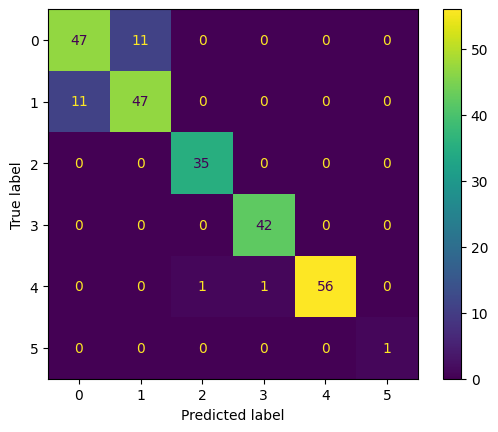

In [2]:
    X_train = []
    y_train = []
    for data, label in tqdm(train_dataset, total=len(train_dataset), desc='Iterating over train dataset'):
        feats = cluster_feats.forward(data)
        arr = feats.to_vector()
        X_train.append(arr)
        y_train.append(label)
    X_train = np.array(X_train)
    y_train = np.array(y_train)
    
    X_valid = []
    y_valid = []
    for data, label in tqdm(valid_dataset, total=len(valid_dataset), desc='Iterating over valid dataset'):
        feats = cluster_feats.forward(data)
        arr = feats.to_vector()
        X_valid.append(arr)
        y_valid.append(label)
    X_valid = np.array(X_valid)
    y_valid = np.array(y_valid)

    run_random_forest(X_train, y_train, X_valid, y_valid)